<a href="https://colab.research.google.com/github/charlie-aashutosh/100-Next-Gen-Engg-C5/blob/main/Sequential_Patient_Risk_Assessment_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Patient Risk Assessment Workflow

- Agent 1 (Node1) for - Assessment of Patient Data
- Agent 2 (Node2) for - Recommendation and Next Steps


In [1]:
!pip install langgraph langchain langchain-google-genai langchain-core langchain-community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 12.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 48.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 32.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.2 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1

In [2]:
import os
import getpass

os.environ["GEMINI_API_KEY"]=getpass.getpass("Enter Gemini API Key")

Enter Gemini API Key··········


In [3]:
from langchain_google_genai import ChatGoogleGenerativeAI

In [7]:
from langchain_core.prompts import ChatPromptTemplate

In [8]:
from langgraph.graph import StateGraph, START, END #START and END are dummy nodes

In [12]:
from langchain_core.output_parsers import StrOutputParser

In [4]:
llm=ChatGoogleGenerativeAI(
    model='gemini-3.6-flash'
)

In [5]:
from typing import TypedDict
class PatientState(TypedDict):

  #input
  patient_data:dict

  #output
  risk_assessment:str
  recommendations:str
  final_report:str

In [6]:
class PatientRiskOutput(TypedDict):
  risk_level:str
  findings=str
  missing_information:str
  explanation:str

class TriageOutput(TypedDict):
  recommendations:str
  urgency:str
  reason:str
  next_steps:str

In [13]:
#creating our first node
def assess_patient(state:PatientState):
  prompt=ChatPromptTemplate.from_template("""
  You are assisting in reviewing the following patient information: {patient_data}

  Your responsibility is:
  1. To understand the symptoms and vital measurements
  2. Identify potential risks indicators
  3. Mention information if it is missing
  4. To provide a reasoned risk assessment

  Do not diagnose the patient, do not invent missing medical history etc,"""
  )
  chain=prompt|llm|StrOutputParser()
  result=chain.invoke({"patient_data":state["patient_data"]})

  return {
      "risk_assessment":result
  }

In [30]:
#creating our second node
def recommend_triage(state:PatientState):
  prompt=ChatPromptTemplate.from_template("""
  You are an assistant to a Healthcare Professional and here is the patient data: {patient_data}
  and patient risk assessment: {risk_assessment}

  Based on the available information, do the following:
  1. Recommend an appropriate next step
  2. Explain why you recommended it
  3. Explain the urgency
  4. Categorize the urgency

  Return a structured recommendation"""
  )
  chain=prompt|llm|StrOutputParser()
  result=chain.invoke({
      "patient_data":state["patient_data"],
      "risk_assessment":state["risk_assessment"]
  })

  return {
      "recommendations":result}

In [31]:
graph=StateGraph(PatientState)

#adding the nodes
graph.add_node("assess_patient",assess_patient)
graph.add_node("recommend_triage",recommend_triage)

#adding the edges
graph.add_edge(START, "assess_patient")
graph.add_edge("assess_patient", "recommend_triage")
graph.add_edge("recommend_triage", END)

In [32]:
workflow=graph.compile()

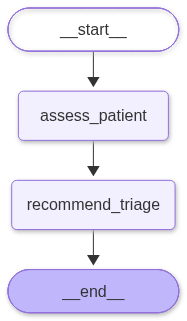

In [33]:
workflow

In [34]:
result = workflow.invoke({
    "patient_data": {
        "age": 28,
        "symptoms": "mild seasonal allergies",
        "blood_pressure": 118,
        "duration": "1 day"
    }
})

In [35]:
print(result["risk_assessment"])

Here is the review of the provided patient information:

### 1. Understanding Symptoms and Vital Measurements
* **Age:** 28 years old (young adult).
* **Reported Symptoms:** Mild seasonal allergies. 
* **Duration:** Short onset (1 day).
* **Blood Pressure:** 118 mmHg. This systolic reading falls within the standard normal range for an adult (less than 120 mmHg).

---

### 2. Potential Risk Indicators
* **Current Risk:** Based strictly on the provided data, there are **no immediate high-risk indicators**. 
* **Watch-out Indicators:** While the symptoms are described as "mild," generic risks associated with allergic presentations involve monitoring for signs of systemic or severe allergic reactions (such as sudden shortness of breath, wheezing, swelling of the face or throat, or dizziness). None of these are indicated in the current note.

---

### 3. Missing Information
To perform a comprehensive clinical review, the following details are missing:
* **Complete Blood Pressure Reading:** 

In [37]:
print(result['recommendations'])

Here is the structured recommendation based on the patient data and risk assessment:

---

### 1. Recommended Next Step
* **Initiate Symptomatic Management & Complete Intake:** 
  * Recommend over-the-counter (OTC) symptomatic relief (e.g., a second-generation oral antihistamine such as cetirizine or loratadine, and/or saline nasal spray) as deemed appropriate by the treating provider.
  * Complete the clinical intake during a routine interaction by gathering missing information: diastolic blood pressure, full set of vitals, specific symptom details, and past medical/allergy history (specifically looking for an asthma history).
  * Provide standard patient education on monitoring for severe allergic reactions (e.g., shortness of breath, wheezing, swelling of the lips, tongue, or throat).

---

### 2. Rationale for Recommendation
* **Low Clinical Risk:** The patient is a young, healthy adult with mild symptoms of short duration (1 day) and a normal systolic blood pressure reading (118 m